# Implementasi Metode Image Enhancement Menggunakan Histogram Equalization pada Citra Digital

**Mata Kuliah:** Pengolahan Citra Digital

| Nama | Fauzan |

| NIM | *24260057* |

| Program Studi | Teknik Informatika |

---

## Bagian 2: Latar Belakang

Foto yang diambil dalam kondisi pencahayaan buruk (terlalu gelap, terlalu terang, atau berkabut) sering terlihat **pucat dan kurang jelas**. Detail pada gambar sulit dilihat karena nilai intensitas pikselnya hanya mengumpul pada rentang yang sempit, atau dengan kata lain **kontras citra rendah**.

Dalam pengolahan citra digital, perbaikan kualitas visual seperti ini disebut **Image Enhancement** (peningkatan kualitas citra). Salah satu metode yang paling dasar dan populer adalah **Histogram Equalization**, yaitu metode yang menyebarkan nilai intensitas piksel agar lebih merata pada seluruh rentang 0-255, sehingga kontras meningkat dan detail lebih mudah terlihat.

Pada praktikum ini, metode Histogram Equalization diimplementasikan menggunakan bahasa Python dengan library OpenCV, NumPy, Matplotlib, dan Pillow.

## Bagian 3: Tujuan Praktikum

1. Memahami konsep citra digital, grayscale, dan histogram citra.
2. Memahami cara kerja metode Histogram Equalization.
3. Mengimplementasikan Histogram Equalization menggunakan Python (secara manual dengan NumPy dan dengan fungsi bawaan OpenCV).
4. Membandingkan citra dan histogram sebelum dan sesudah proses.
5. Menganalisis pengaruh Histogram Equalization terhadap kualitas dan keterlihatan detail citra.

## Bagian 4: Landasan Teori

### 4.1 Citra Digital
Citra digital adalah gambar yang disimpan dalam bentuk **matriks piksel**. Setiap piksel memiliki nilai intensitas.
- **Citra RGB**: setiap piksel punya 3 nilai (Red, Green, Blue), masing-masing 0-255.
- **Citra grayscale (keabuan)**: setiap piksel hanya punya 1 nilai, dari **0 (hitam)** sampai **255 (putih)**.

### 4.2 Konversi RGB ke Grayscale
Citra RGB diubah menjadi grayscale dengan rumus pembobotan yang disesuaikan dengan sensitivitas mata manusia:

$$Gray = 0{,}299 \times R + 0{,}587 \times G + 0{,}114 \times B$$

### 4.3 Histogram Citra
Histogram citra adalah grafik yang menunjukkan **jumlah piksel pada setiap tingkat intensitas**.
- Sumbu X: tingkat intensitas (0-255).
- Sumbu Y: jumlah piksel.

Cara membaca histogram:
- Menumpuk di kiri → citra **gelap**.
- Menumpuk di kanan → citra **terang**.
- Menumpuk sempit di tengah → citra **kontras rendah (pucat)**.
- Tersebar merata di 0-255 → citra **kontras baik**.

### 4.3 Histogram Equalization
Histogram Equalization (HE) adalah metode untuk **meratakan distribusi intensitas** citra. Langkah-langkahnya:

1. Hitung histogram citra, yaitu jumlah piksel $n_k$ untuk setiap intensitas $k$ ($k = 0, 1, \dots, L-1$, dengan $L = 256$).
2. Hitung probabilitas tiap intensitas (PDF):
$$p(k) = \frac{n_k}{N}$$
dengan $N$ adalah jumlah seluruh piksel.
3. Hitung distribusi kumulatif (CDF):
$$cdf(k) = \sum_{j=0}^{k} p(j)$$
4. Petakan intensitas lama ke intensitas baru:
$$s_k = round\left(\frac{cdf(k) - cdf_{min}}{1 - cdf_{min}} \times (L-1)\right)$$
5. Ganti setiap piksel dengan nilai barunya.

**Kelebihan:** sederhana, cepat, otomatis (tanpa parameter), efektif untuk citra berkontras rendah.

**Kekurangan:** dapat membuat citra tampak tidak natural, memperkuat *noise*, dan bisa kehilangan detail pada area yang sudah terang atau gelap. HE juga bekerja pada seluruh citra secara global, bukan per area.

## Bagian 5: Instalasi dan Pemanggilan Library

Library yang digunakan:
- **OpenCV (`cv2`)**: konversi grayscale dan fungsi `equalizeHist`.
- **NumPy**: operasi matriks dan perhitungan histogram.
- **Matplotlib**: menampilkan citra dan grafik histogram.
- **Pillow (`PIL`)**: membaca file gambar.

Di Google Colab library ini umumnya sudah tersedia. Jalankan cell instalasi jika menjalankan di komputer sendiri.

In [1]:
# Instalasi library (aman dijalankan ulang; lewati jika sudah terpasang)
%pip install -q opencv-python numpy matplotlib pillow

Note: you may need to restart the kernel to use updated packages.



[notice] A new release of pip is available: 23.0.1 -> 26.2.2
[notice] To update, run: python.exe -m pip install --upgrade pip


In [2]:
import os
import numpy as np
import cv2
import matplotlib.pyplot as plt
from PIL import Image

# Pengaturan tampilan grafik
plt.rcParams["figure.dpi"] = 100
plt.rcParams["axes.grid"] = False

print("NumPy      :", np.__version__)
print("OpenCV     :", cv2.__version__)
print("Pillow     :", Image.__version__)

NumPy      : 2.2.6
OpenCV     : 5.0.0
Pillow     : 12.2.0


## Bagian 6: Memasukkan / Mengunggah Gambar

Ada dua cara memasukkan gambar:

- **Google Colab:** jalankan cell di bawah, lalu klik tombol *Choose Files* dan pilih gambar (`.jpg`, `.jpeg`, atau `.png`).
- **Jupyter lokal:** isi variabel `IMAGE_PATH` dengan nama/lokasi file gambar, contoh `IMAGE_PATH = "foto_gelap.jpg"`.

> **Saran gambar:** gunakan foto yang **gelap, terlalu terang, atau berkabut** agar efek Histogram Equalization terlihat jelas.
>
> Jika tidak ada gambar yang dimasukkan, program memakai **gambar contoh buatan** (low contrast) hanya agar notebook tetap bisa berjalan. Untuk laporan, gunakan gambar milikmu sendiri.

In [3]:
# Untuk Jupyter lokal: isi path gambar di sini, contoh: "foto_gelap.jpg"
IMAGE_PATH = "WhatsApp Image 2026-10-25 at 20.43.48.jpeg"

# Untuk Google Colab: unggah gambar melalui dialog
try:
    from google.colab import files
    uploaded = files.upload()
    if uploaded:
        IMAGE_PATH = list(uploaded.keys())[0]
        print("Gambar yang diunggah:", IMAGE_PATH)
except ImportError:
    print("Bukan Google Colab. Menggunakan IMAGE_PATH =", IMAGE_PATH)

Bukan Google Colab. Menggunakan IMAGE_PATH = WhatsApp Image 2026-10-25 at 20.43.48.jpeg


In [4]:
MAX_SIZE = 1000  # sisi terpanjang maksimum (piksel), agar proses & tampilan tetap ringan

def buat_gambar_contoh(h=400, w=600):
    """Membuat gambar contoh berkontras rendah (hanya untuk demo jika tidak ada gambar)."""
    rng = np.random.default_rng(42)
    yy, xx = np.mgrid[0:h, 0:w]
    dasar = 0.5 * (xx / w) + 0.5 * (yy / h)                       # gradasi halus
    lingkaran = ((xx - 180) ** 2 + (yy - 200) ** 2) < 90 ** 2      # objek lingkaran
    persegi = (abs(xx - 430) < 80) & (abs(yy - 210) < 80)          # objek persegi
    citra = dasar.copy()
    citra[lingkaran] += 0.25
    citra[persegi] -= 0.25
    citra += rng.normal(0, 0.015, size=(h, w))                     # sedikit noise
    citra = np.clip(citra, 0, 1)
    citra = 70 + citra * 60                                        # dipadatkan ke rentang sempit (70-130)
    return np.stack([citra * 1.00, citra * 0.95, citra * 0.90], axis=-1).astype(np.uint8)

if IMAGE_PATH and os.path.exists(IMAGE_PATH):
    img_pil = Image.open(IMAGE_PATH).convert("RGB")   # pastikan 3 kanal (RGB)
    img_pil.thumbnail((MAX_SIZE, MAX_SIZE))           # perkecil jika terlalu besar
    img_rgb = np.array(img_pil)
    sumber = f"file: {IMAGE_PATH}"
else:
    img_rgb = buat_gambar_contoh()
    sumber = "GAMBAR CONTOH BUATAN (belum memakai gambar sendiri)"
    print("PERHATIAN: tidak ada gambar yang dimasukkan. Menggunakan gambar contoh.")

print("Sumber gambar :", sumber)
print("Ukuran citra  :", img_rgb.shape, "(tinggi, lebar, kanal)")
print("Tipe data     :", img_rgb.dtype)

Sumber gambar : file: WhatsApp Image 2026-10-25 at 20.43.48.jpeg
Ukuran citra  : (1000, 562, 3) (tinggi, lebar, kanal)
Tipe data     : uint8


## Bagian 7: Menampilkan Citra Asli

Citra asli ditampilkan dalam format RGB (berwarna). Matplotlib memakai urutan kanal RGB, sehingga gambar yang dibaca dengan Pillow dapat langsung ditampilkan.

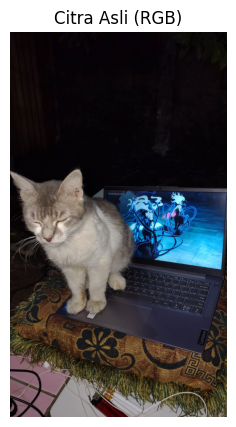

In [5]:
plt.figure(figsize=(7, 5))
plt.imshow(img_rgb)
plt.title("Citra Asli (RGB)")
plt.axis("off")
plt.show()

## Bagian 8: Mengubah Citra Menjadi Grayscale

Histogram Equalization klasik bekerja pada citra **1 kanal (grayscale)**. Citra RGB diubah menjadi grayscale dengan `cv2.cvtColor`, sehingga setiap piksel hanya memiliki satu nilai intensitas (0-255).

Ukuran citra grayscale : (1000, 562)
Nilai piksel minimum   : 0
Nilai piksel maksimum  : 250


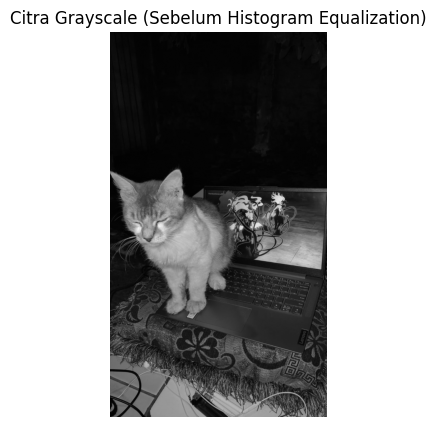

In [6]:
img_gray = cv2.cvtColor(img_rgb, cv2.COLOR_RGB2GRAY)

print("Ukuran citra grayscale :", img_gray.shape)
print("Nilai piksel minimum   :", img_gray.min())
print("Nilai piksel maksimum  :", img_gray.max())

plt.figure(figsize=(7, 5))
plt.imshow(img_gray, cmap="gray", vmin=0, vmax=255)
plt.title("Citra Grayscale (Sebelum Histogram Equalization)")
plt.axis("off")
plt.show()

## Bagian 9: Histogram Citra Sebelum Diproses

Histogram menunjukkan sebaran intensitas piksel. Perhatikan **di mana batang histogram menumpuk** dan **seberapa lebar sebarannya**.

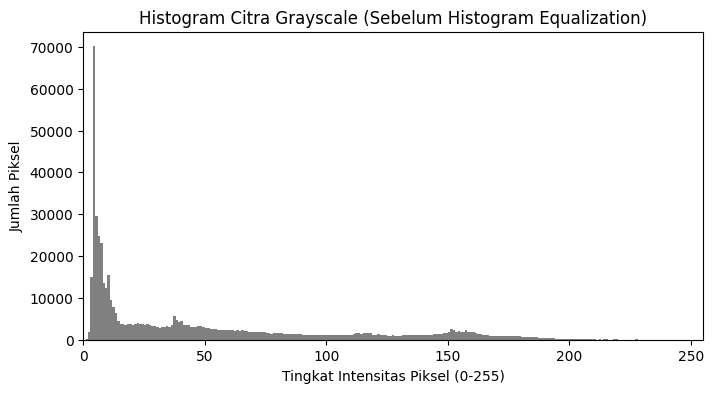

In [7]:
plt.figure(figsize=(8, 4))
plt.hist(img_gray.ravel(), bins=256, range=(0, 256), color="gray")
plt.title("Histogram Citra Grayscale (Sebelum Histogram Equalization)")
plt.xlabel("Tingkat Intensitas Piksel (0-255)")
plt.ylabel("Jumlah Piksel")
plt.xlim(0, 255)
plt.show()

## Bagian 10: Implementasi Histogram Equalization

Metode ini diimplementasikan dengan **dua cara**:

1. **Manual dengan NumPy**: mengikuti langkah teori (histogram → PDF → CDF → pemetaan), agar proses perhitungannya terlihat jelas.
2. **Fungsi bawaan OpenCV** `cv2.equalizeHist()`, sebagai pembanding/verifikasi.

Hasil kedua cara seharusnya sama atau hampir sama (perbedaan hanya karena pembulatan).

In [8]:
def histogram_equalization_manual(citra_gray):
    """Histogram Equalization manual untuk citra grayscale uint8.
    Mengembalikan: citra hasil, histogram asli, CDF asli, tabel pemetaan (LUT)."""
    # 1. Histogram: jumlah piksel untuk tiap intensitas 0-255
    hist = np.bincount(citra_gray.ravel(), minlength=256)
    # 2. PDF: probabilitas tiap intensitas
    pdf = hist / citra_gray.size
    # 3. CDF: distribusi kumulatif
    cdf = np.cumsum(pdf)
    # 4. Pemetaan intensitas lama -> intensitas baru
    cdf_min = cdf[cdf > 0].min()
    if cdf_min >= 1.0:                      # citra seragam (semua piksel sama)
        lut = np.arange(256, dtype=np.uint8)
    else:
        lut = np.round((cdf - cdf_min) / (1 - cdf_min) * 255)
        lut = np.clip(lut, 0, 255).astype(np.uint8)
    # 5. Terapkan pemetaan ke seluruh piksel
    hasil = lut[citra_gray]
    return hasil, hist, cdf, lut

# Cara 1: manual (NumPy)
img_eq_manual, hist_before, cdf_before, lut = histogram_equalization_manual(img_gray)

# Cara 2: bawaan OpenCV
img_eq_cv = cv2.equalizeHist(img_gray)

# Verifikasi
selisih = np.abs(img_eq_manual.astype(int) - img_eq_cv.astype(int))
print("Selisih maksimum manual vs OpenCV :", selisih.max())
print("Persentase piksel yang berbeda    : {:.4f}%".format(100 * np.mean(selisih > 0)))

# Citra hasil yang dipakai pada bagian berikutnya
img_eq = img_eq_cv

Selisih maksimum manual vs OpenCV : 0
Persentase piksel yang berbeda    : 0.0000%


In [9]:
# Menampilkan sebagian tabel pemetaan (intensitas lama -> intensitas baru)
print("Intensitas lama -> baru (hanya intensitas yang benar-benar muncul, maks 15 baris):")
muncul = np.where(hist_before > 0)[0]
langkah = max(1, len(muncul) // 15)
for k in muncul[::langkah]:
    print(f"  {k:3d} -> {lut[k]:3d}   (jumlah piksel: {hist_before[k]})")

Intensitas lama -> baru (hanya intensitas yang benar-benar muncul, maks 15 baris):
    0 ->   0   (jumlah piksel: 33)
   16 -> 110   (jumlah piksel: 3751)
   32 -> 135   (jumlah piksel: 2989)
   48 -> 162   (jumlah piksel: 3177)
   64 -> 180   (jumlah piksel: 2202)
   80 -> 193   (jumlah piksel: 1495)
   96 -> 202   (jumlah piksel: 1063)
  112 -> 211   (jumlah piksel: 1516)
  128 -> 220   (jumlah piksel: 938)
  144 -> 228   (jumlah piksel: 1308)
  160 -> 241   (jumlah piksel: 1821)
  176 -> 249   (jumlah piksel: 817)
  192 -> 253   (jumlah piksel: 319)
  208 -> 254   (jumlah piksel: 88)
  224 -> 255   (jumlah piksel: 39)
  241 -> 255   (jumlah piksel: 5)


## Bagian 11: Menampilkan Citra Hasil Pengolahan

Berikut citra grayscale setelah diterapkan Histogram Equalization.

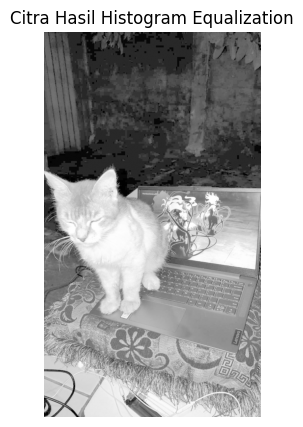

Tersimpan: hasil_grayscale.png dan hasil_histogram_equalization.png


In [10]:
plt.figure(figsize=(7, 5))
plt.imshow(img_eq, cmap="gray", vmin=0, vmax=255)
plt.title("Citra Hasil Histogram Equalization")
plt.axis("off")
plt.show()

# Simpan hasil ke file (opsional, dapat diunduh untuk lampiran laporan)
cv2.imwrite("hasil_grayscale.png", img_gray)
cv2.imwrite("hasil_histogram_equalization.png", img_eq)
print("Tersimpan: hasil_grayscale.png dan hasil_histogram_equalization.png")

## Bagian 12: Histogram Setelah Pengolahan

Setelah Histogram Equalization, sebaran intensitas seharusnya **lebih lebar dan lebih merata** pada rentang 0-255. Kurva **CDF** (garis merah) juga ditampilkan; pada hasil yang ideal, CDF mendekati garis lurus diagonal.

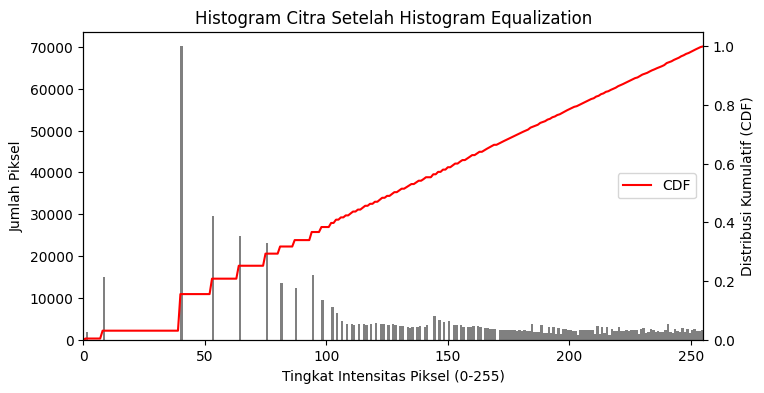

In [11]:
hist_after = np.bincount(img_eq.ravel(), minlength=256)
cdf_after = np.cumsum(hist_after) / img_eq.size

fig, ax = plt.subplots(figsize=(8, 4))
ax.hist(img_eq.ravel(), bins=256, range=(0, 256), color="gray")
ax.set_title("Histogram Citra Setelah Histogram Equalization")
ax.set_xlabel("Tingkat Intensitas Piksel (0-255)")
ax.set_ylabel("Jumlah Piksel")
ax.set_xlim(0, 255)

ax2 = ax.twinx()
ax2.plot(np.arange(256), cdf_after, color="red", linewidth=1.5, label="CDF")
ax2.set_ylabel("Distribusi Kumulatif (CDF)")
ax2.set_ylim(0, 1.05)
ax2.legend(loc="center right")
plt.show()

## Bagian 13: Perbandingan Sebelum dan Sesudah Pengolahan

Bagian ini menampilkan citra dan histogram **berdampingan** sehingga mudah dibandingkan dan siap dipakai sebagai gambar laporan.

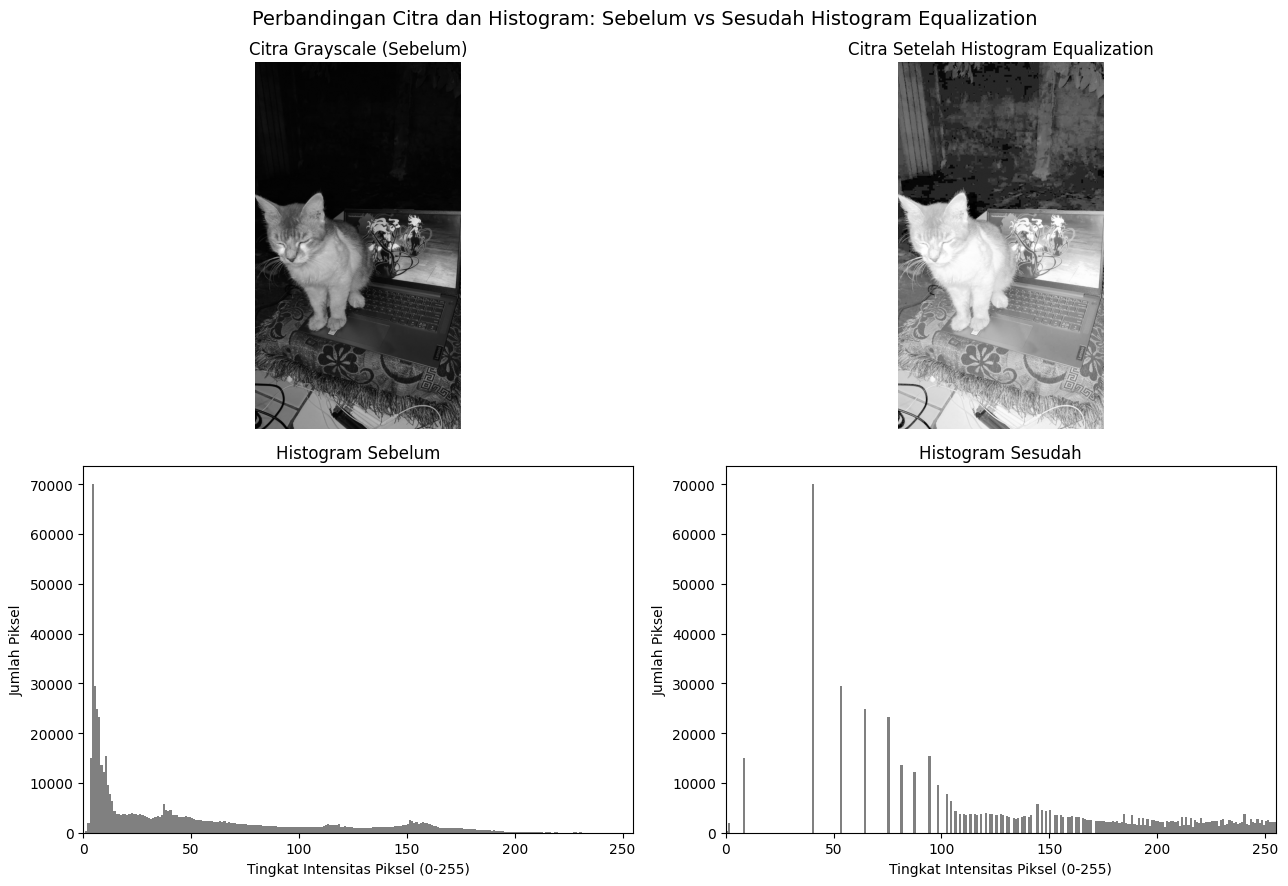

In [12]:
fig, axes = plt.subplots(2, 2, figsize=(13, 9))

# Baris 1: citra
axes[0, 0].imshow(img_gray, cmap="gray", vmin=0, vmax=255)
axes[0, 0].set_title("Citra Grayscale (Sebelum)")
axes[0, 0].axis("off")

axes[0, 1].imshow(img_eq, cmap="gray", vmin=0, vmax=255)
axes[0, 1].set_title("Citra Setelah Histogram Equalization")
axes[0, 1].axis("off")

# Baris 2: histogram (sumbu Y dibuat sama agar adil dibandingkan)
batas_y = max(hist_before.max(), hist_after.max()) * 1.05

axes[1, 0].hist(img_gray.ravel(), bins=256, range=(0, 256), color="gray")
axes[1, 0].set_title("Histogram Sebelum")
axes[1, 0].set_xlabel("Tingkat Intensitas Piksel (0-255)")
axes[1, 0].set_ylabel("Jumlah Piksel")
axes[1, 0].set_xlim(0, 255)
axes[1, 0].set_ylim(0, batas_y)

axes[1, 1].hist(img_eq.ravel(), bins=256, range=(0, 256), color="gray")
axes[1, 1].set_title("Histogram Sesudah")
axes[1, 1].set_xlabel("Tingkat Intensitas Piksel (0-255)")
axes[1, 1].set_ylabel("Jumlah Piksel")
axes[1, 1].set_xlim(0, 255)
axes[1, 1].set_ylim(0, batas_y)

plt.suptitle("Perbandingan Citra dan Histogram: Sebelum vs Sesudah Histogram Equalization", fontsize=14)
plt.tight_layout()
plt.savefig("perbandingan_histogram_equalization.png", dpi=150, bbox_inches="tight")
plt.show()

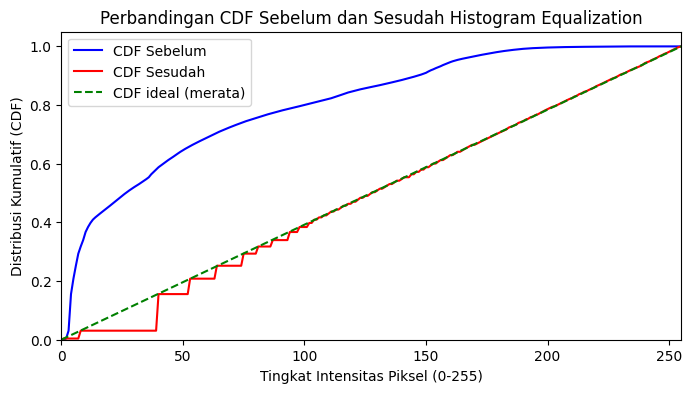

In [13]:
# Perbandingan CDF (kurva distribusi kumulatif) sebelum dan sesudah
plt.figure(figsize=(8, 4))
plt.plot(np.arange(256), cdf_before, label="CDF Sebelum", color="blue")
plt.plot(np.arange(256), cdf_after, label="CDF Sesudah", color="red")
plt.plot([0, 255], [0, 1], "--", color="green", label="CDF ideal (merata)")
plt.title("Perbandingan CDF Sebelum dan Sesudah Histogram Equalization")
plt.xlabel("Tingkat Intensitas Piksel (0-255)")
plt.ylabel("Distribusi Kumulatif (CDF)")
plt.xlim(0, 255)
plt.ylim(0, 1.05)
plt.legend()
plt.show()

## Bagian 14: Analisis dan Pembahasan Hasil

Analisis dibuat dalam dua tahap agar **sesuai dengan hasil sebenarnya**:

1. Cell kode di bawah menghitung **statistik citra** dan menampilkan **interpretasi otomatis** dari angka-angkanya.
2. Setelah itu, lengkapi **template pembahasan** dengan kata-katamu sendiri berdasarkan output dan gambar yang muncul.

In [14]:
def statistik(citra):
    hist = np.bincount(citra.ravel(), minlength=256)
    p = hist / citra.size
    p = p[p > 0]
    return {
        "Rata-rata intensitas (brightness)": citra.mean(),
        "Standar deviasi (kontras)": citra.std(),
        "Intensitas minimum": int(citra.min()),
        "Intensitas maksimum": int(citra.max()),
        "Rentang dinamis (maks - min)": int(citra.max()) - int(citra.min()),
        "Jumlah level intensitas berbeda": int(np.count_nonzero(hist)),
        "Entropi (bit)": float(-(p * np.log2(p)).sum()),
    }

s_before = statistik(img_gray)
s_after = statistik(img_eq)

print(f"{'Parameter':40s} {'Sebelum':>12s} {'Sesudah':>12s}")
print("-" * 66)
for k in s_before:
    print(f"{k:40s} {s_before[k]:12.2f} {s_after[k]:12.2f}")

Parameter                                     Sebelum      Sesudah
------------------------------------------------------------------
Rata-rata intensitas (brightness)               50.05       131.08
Standar deviasi (kontras)                       54.17        69.78
Intensitas minimum                               0.00         0.00
Intensitas maksimum                            250.00       255.00
Rentang dinamis (maks - min)                   250.00       255.00
Jumlah level intensitas berbeda                249.00       139.00
Entropi (bit)                                    6.59         6.34


In [15]:
# Interpretasi otomatis berdasarkan angka hasil perhitungan
mean_b, std_b = s_before["Rata-rata intensitas (brightness)"], s_before["Standar deviasi (kontras)"]
mean_a, std_a = s_after["Rata-rata intensitas (brightness)"], s_after["Standar deviasi (kontras)"]

# 1. Kondisi sebelum diproses
if mean_b < 85:
    kondisi = "cenderung GELAP (rata-rata intensitas rendah)"
elif mean_b > 170:
    kondisi = "cenderung TERANG (rata-rata intensitas tinggi)"
else:
    kondisi = "memiliki kecerahan SEDANG"
kontras = "KONTRAS RENDAH (sebaran intensitas sempit)" if std_b < 50 else "kontras CUKUP BAIK (sebaran intensitas cukup lebar)"
print("1. Kondisi sebelum diproses :", kondisi, "dan", kontras)

# 2. Perubahan rentang & kontras
print(f"2. Rentang dinamis          : {s_before['Rentang dinamis (maks - min)']} -> {s_after['Rentang dinamis (maks - min)']}")
perubahan_std = std_a - std_b
if perubahan_std > 5:
    print(f"3. Kontras (std)            : NAIK dari {std_b:.1f} menjadi {std_a:.1f}")
elif perubahan_std < -5:
    print(f"3. Kontras (std)            : TURUN dari {std_b:.1f} menjadi {std_a:.1f} (citra sebelumnya sudah sangat kontras)")
else:
    print(f"3. Kontras (std)            : relatif tetap ({std_b:.1f} -> {std_a:.1f})")

# 3. Perubahan kecerahan
print(f"4. Kecerahan rata-rata      : {mean_b:.1f} -> {mean_a:.1f}")

# 4. Entropi (ukuran keragaman informasi intensitas)
print(f"5. Entropi                  : {s_before['Entropi (bit)']:.2f} -> {s_after['Entropi (bit)']:.2f} bit")
print()
print("Catatan: ini hanya interpretasi dari angka. Tetap lihat gambar untuk menilai detail & kewajaran citra.")

1. Kondisi sebelum diproses : cenderung GELAP (rata-rata intensitas rendah) dan kontras CUKUP BAIK (sebaran intensitas cukup lebar)
2. Rentang dinamis          : 250 -> 255
3. Kontras (std)            : NAIK dari 54.2 menjadi 69.8
4. Kecerahan rata-rata      : 50.0 -> 131.1
5. Entropi                  : 6.59 -> 6.34 bit

Catatan: ini hanya interpretasi dari angka. Tetap lihat gambar untuk menilai detail & kewajaran citra.


### Template Pembahasan (lengkapi sesuai hasil yang muncul)

> Teks dalam tanda `[...]` harus kamu sesuaikan dengan output dan gambar pada notebook-mu. Hapus pilihan yang tidak sesuai.

**1. Kondisi citra sebelum diproses**
Citra asli berupa *[jelaskan objek/foto yang dipakai]*. Berdasarkan histogram sebelum proses, intensitas piksel *[menumpuk di sisi kiri / menumpuk di sisi kanan / menumpuk sempit di tengah / sudah tersebar luas]*, dengan rentang intensitas *[min]* sampai *[maks]* dan standar deviasi *[nilai]*. Hal ini menunjukkan citra *[gelap / terang / berkontras rendah / cukup baik]*, sehingga detail pada area *[sebutkan area]* *[sulit / cukup]* terlihat.

**2. Perubahan intensitas piksel setelah Histogram Equalization**
Setelah proses, rentang intensitas menjadi *[min baru]* sampai *[maks baru]* dan standar deviasi menjadi *[nilai]*. Intensitas piksel yang sebelumnya *[menumpuk di ...]* kini *[tersebar lebih merata pada rentang 0-255]*. Kecerahan rata-rata berubah dari *[nilai]* menjadi *[nilai]*.

**3. Perbedaan histogram sebelum dan sesudah**
Histogram sebelum *[bentuknya: sempit / condong ke kiri / dll.]*, sedangkan histogram sesudah *[bentuknya: lebih lebar / lebih merata, namun muncul celah (gap) antar batang karena intensitas dipetakan ulang]*. Kurva CDF *[mendekati garis diagonal ideal / belum sepenuhnya diagonal]*.

**4. Kelebihan dan kekurangan Histogram Equalization**
- *Kelebihan:* sederhana, cepat, otomatis tanpa parameter, dan efektif meningkatkan kontras pada citra yang intensitasnya sempit.
- *Kekurangan:* bersifat global sehingga area tertentu bisa menjadi terlalu terang/gelap, dapat memperkuat noise, hasil bisa tampak kurang natural, dan histogram hasil tidak benar-benar rata karena jumlah level intensitas terbatas (diskrit). *[Tambahkan pengamatan dari hasilmu, misalnya area yang menjadi terlalu terang atau noise yang menguat.]*

**5. Apakah keterlihatan detail meningkat?**
*[Ya / Sebagian / Tidak]*. Detail pada *[area ... ]* menjadi *[lebih jelas / tetap / hilang]* karena *[alasan berdasarkan gambar dan histogram]*.

## Bagian 15: Kesimpulan

*(Sesuaikan dengan hasil percobaanmu.)*

1. Histogram Equalization adalah metode image enhancement yang meratakan distribusi intensitas piksel berdasarkan CDF citra, sehingga kontras meningkat.
2. Implementasi manual dengan NumPy menghasilkan citra yang sama (atau hampir sama) dengan fungsi `cv2.equalizeHist()`.
3. Pada citra yang digunakan, metode ini *[berhasil / cukup berhasil / kurang berhasil]* meningkatkan kontras dan keterlihatan detail, ditunjukkan oleh *[sebaran histogram yang lebih lebar, kenaikan standar deviasi, dll.]*.
4. Keterbatasan metode ini adalah sifatnya yang global, sehingga *[tuliskan efek samping yang kamu amati, misalnya noise meningkat atau area menjadi terlalu terang]*.
5. Untuk pengembangan, dapat digunakan metode lanjutan seperti **CLAHE** (*Contrast Limited Adaptive Histogram Equalization*) yang bekerja per area dan membatasi penguatan noise.

---
*Selesai.*